In [8]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
from vae_training import Modeltraining
from data_prep import DataPrep
from portfolio_eval import DistanceMetrics, PriceData, PortfolioSelection, DiversificationAnalysis
import itertools

In [9]:
data = DataPrep.full_data_prep(0.7, 0.15, 0.15, '2023-12-31', 1)
X_train_scaled = data['train']
X_train_mask = data['train_mask']
X_val_scaled = data['val']
X_val_mask = data['val_mask']
X_test_scaled = data['test']
X_test_mask = data['test_mask']
test_entities = data['test_entities']
val_entities = data['val_entities']
usable_features = data['usable_features']
scaler = data['scaler']

Train Rows: 11219 (5548 Firmen)
Val Rows:   1181 (1189 Firmen)
Test Rows:  1186 (1190 Firmen)


In [3]:
returns = PriceData.execute(val_entities, '1wk', '2024-01-01', '2026-09-22', 0.05)

$RMAX: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22)
$TBRG: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22) (Yahoo error = "No data found, symbol may be delisted")
$EIFF.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22)
$BRM.MI: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22) (Yahoo error = "No data found, symbol may be delisted")
$MLVRE.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22)
$MLEFA.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22) (Yahoo error = "No data found, symbol may be delisted")
$1246.HK: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22) (Yahoo error = "No data found, symbol may be delisted")
$MLVRF.PA: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22)
$0699.HK: possibly delisted; no price data found  (1wk 2024-01-01 -> 2026-09-22)
$LBRDK: possibly delisted; no price data found  (1w

Eingangs-Ticker:          1181
Nutzbare Ticker nach 0.05 Filterung: 1069


In [17]:
num_assets = 10

emb_dim = 1
hidden_dims = (256, 128)
latent_dim = 8
dropout_rate = 0.15
batch_size = 256
lr = 0.001
epochs = 100
beta = 0.005
device = "cuda"
print_every = 10
eval_every = 10
kl_warmup_epochs = 50
free_bits = 0.0
model, history = Modeltraining.train_vae(X_train_scaled, X_train_mask, X_val_scaled, X_val_mask, 
                                                emb_dim=emb_dim, hidden_dims=hidden_dims, latent_dim=latent_dim, dropout_rate=dropout_rate,
                                                batch_size=batch_size, lr=lr, epochs=epochs, beta=beta, device=device, 
                                                print_every=print_every, eval_every=eval_every, feature_names=usable_features, 
                                                kl_warmup_epochs=kl_warmup_epochs, free_bits=free_bits, scaler=scaler, early_stopping_patience=15)

latent_mu = Modeltraining.get_latent_embeddings(model, X_val_scaled, X_val_mask, device=device)
cluster_portfolio = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, val_entities, returns.columns, 5)
vae_ergebnis_cluster = DiversificationAnalysis.diversification_ratio(returns, cluster_portfolio)

Epoch   1 | train: loss=1.4118 recon=1.4109 kl=9.0020 | val: loss=1.1123 recon=1.1115 kl=8.0089 val_rel_err=142.38%
Epoch  10 | train: loss=0.5528 recon=0.5283 kl=24.4608 | val: loss=0.4876 recon=0.4632 kl=24.3325 val_rel_err=131.01%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.3242 MAE=0.5161 NMAE_STD=0.7202
Epoch  20 | train: loss=0.5187 recon=0.4800 kl=19.3107 | val: loss=0.4681 recon=0.4303 kl=18.9406 val_rel_err=129.36%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.3399 MAE=0.5087 NMAE_STD=0.7108
Epoch  30 | train: loss=0.5136 recon=0.4614 kl=17.3964 | val: loss=0.4689 recon=0.4181 kl=16.9295 val_rel_err=129.02%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.3257 MAE=0.5036 NMAE_STD=0.7097
Epoch  40 | train: loss=0.5206 recon=0.4562 kl=16.1069 | val: loss=0.4782 recon=0.4152 kl=15.7536 val_rel_err=127.81%
           -> Imputation-Check (val, künstlich versteckt): MSE=1.3502 MAE=0.4999 NMAE_STD=0.7052
Epoch  50 | train: loss=

c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


In [27]:
erg = []
for i in range(101):
    cluster_portfolio = PortfolioSelection.select_cluster_diverse_portfolio(latent_mu, val_entities, returns.columns, 10, random_state=i, use_cosine=False)
    vae_ergebnis_cluster = DiversificationAnalysis.diversification_ratio(returns, cluster_portfolio)
    erg.append(vae_ergebnis_cluster['diversification_ratio'])
print(f'AVG = {np.mean(erg)} STD = {np.std(erg)}')

c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: 

AVG = 2.707466145143051 STD = 0.15043492582752915


c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


In [20]:
vae_ergebnis_cluster

{'diversification_ratio': 1.6828106855378013,
 'portfolio_volatility_annual': 0.33898834215057905,
 'weighted_avg_volatility_annual': 0.5704532044437387,
 'selected_tickers': ['IG.MI', '9936.HK', 'CLYM', 'WST', 'SAB.MI']}

In [25]:
erg_rand = []
for i in range(1000):
    random_portfolio = PortfolioSelection.random_portfolio(10, returns)
    random_ergebnis = DiversificationAnalysis.diversification_ratio(returns, random_portfolio)
    erg_rand.append(random_ergebnis['diversification_ratio'])
print(f'Ergebnis Random Portfolio mit {num_assets} AVG = {np.mean(erg_rand)} STD = {np.std(erg_rand)}')

Ergebnis Random Portfolio mit 10 AVG = 2.300871118334597 STD = 0.30742755578474046


c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Konra\miniforge3\envs\gnn-data\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\Konra\AppData\Local\Temp\ipykernel_9688\4085653912.py:14: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = plt.scatter(


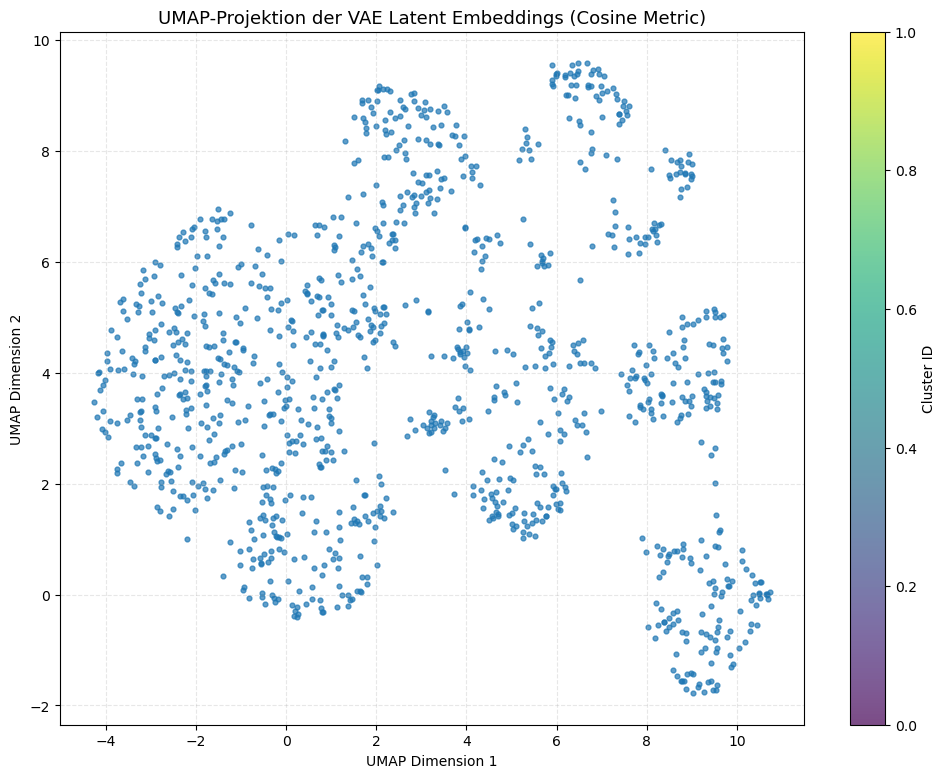

In [12]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(
    n_neighbors=20,      # Balance zwischen lokaler und globaler Struktur
    min_dist=0.4,        # Höherer Wert drückt die Punkte weiter auseinander
    metric='cosine',     # Weit weniger anfällig für den Fluch der Dimensionalität
    random_state=42
)

embedding_2d = reducer.fit_transform(latent_mu)

plt.figure(figsize=(12, 9))
scatter = plt.scatter(
    embedding_2d[:, 0], 
    embedding_2d[:, 1],
    cmap='tab20', 
    s=12,                # Etwas größere Punkte für bessere Lesbarkeit
    alpha=0.7
)

plt.colorbar(scatter, label='Cluster ID')
plt.title('UMAP-Projektion der VAE Latent Embeddings (Cosine Metric)', fontsize=13)
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.grid(True, linestyle='--', alpha=0.3)  # Raster hilft bei der Orientierung
plt.show()